In [3]:
## IMPORT LIBRARIES 
import os 
import numpy as np
import spikeinterface.full as si
import spikeinterface.widgets as sw
import spikeinterface.extractors as se
from spikeinterface.extractors import read_phy
from spikeinterface.preprocessing import whiten, highpass_spatial_filter
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from tqdm import tqdm

In [4]:
### PARAMETERS ### 
root_folder = '/nexus/posix0/MBR-neuralsystems/ephys/GLC6811/GLC6811__g2'
exp_folder = os.path.join(root_folder, 'KS4','wr64_nt0m20_nc64_mcd64_acg1_ccg1.5_car0_spc1_jobs-1_thrd4')
sorter_output = os.path.join(exp_folder, 'sorter_output')
preprocessed_folder = os.path.join(root_folder, 'preprocessed')
analyzer_save = os.path.join(exp_folder, 'si_analyzer')

spikeglx_folder = os.path.join(root_folder, 'GLC6811__g2_imec0')
rec0 = si.read_spikeglx(spikeglx_folder, stream_name='imec0.ap', load_sync_channel=False)

preprocessed_rec = si.load_extractor(preprocessed_folder)
preprocessed_rec

fs = preprocessed_rec.get_sampling_frequency()
nchan = preprocessed_rec.get_num_channels()

ks_preprocessed_file = os.path.join(sorter_output, "temp_wh.dat")
ks_preprocessed_rec = si.read_binary(
    file_paths=ks_preprocessed_file,
    sampling_frequency=fs,
    num_channels=nchan,
    dtype=np.int16
)

sorting = read_phy(sorter_output)

/tmp/ipykernel_83688/2696314884.py:11: DeprecationWarning: load_extractor() is deprecated and will be removed in version 0.104.0. Please use load() instead.
  preprocessed_rec = si.load_extractor(preprocessed_folder)


In [5]:
rec0

SpikeGLXRecordingExtractor: 384 channels - 30000.138084 Hz - 1 segments - 74,579,698 samples 
                            2,485.98s (41.43 minutes) - int16 dtype - 53.34 GiB

In [4]:
ks_preprocessed_rec

BinaryRecordingExtractor: 338 channels - 30000.138084 Hz - 1 segments - 74,580,000 samples 
                          2,485.99s (41.43 minutes) - int16 dtype - 46.95 GiB
  file_paths: ['/nexus/posix0/MBR-neuralsystems/ephys/GLC6811/GLC6811__g2/KS4/wr64_nt0m20_nc64_mcd64_acg1_ccg1.5_car0_spc1_jobs-1_thrd4/sorter_output/temp_wh.dat']

In [5]:
preprocessed_rec

BinaryFolderRecording: 338 channels - 30000.138084 Hz - 1 segments - 74,579,698 samples 
                       2,485.98s (41.43 minutes) - float16 dtype - 46.95 GiB

## SPIKE OVER TRACE

In [6]:
spike_clusters = np.load(os.path.join(sorter_output, 'spike_clusters.npy'))
spike_positions = np.load(os.path.join(sorter_output, 'spike_positions.npy'))
spike_templates = np.load(os.path.join(sorter_output,'spike_templates.npy'))
templates = np.load(os.path.join(sorter_output,'templates.npy'))
channel_positions = np.load(os.path.join(sorter_output,'channel_positions.npy'))
channel_map = np.load(os.path.join(sorter_output,'channel_map.npy')) 
spike_times = np.load(os.path.join(sorter_output, 'spike_times.npy'))
ops = np.load(os.path.join(sorter_output, 'ops.npy'), allow_pickle = True)
fs = ops.item()['fs']


In [7]:
def plot_spikes_on_trace(rec, preprocessed_rec, templates, spike_templates, spike_times, spike_clusters, fs, active_channel_threshold, time_range, sorter_output, rec_name): 
    ### find best channel for each spike ### 
    template_amplitudes = np.max(np.abs(templates),axis=1) #n_templates, n_channels 
    peak_channels_for_template = np.argmax(template_amplitudes, axis = 1) #n_templates

    #map spikes to its template's peak channel 
    all_spike_template_indices = spike_templates.flatten() 
    all_spike_peak_channel = peak_channels_for_template[all_spike_template_indices]

    ### time window filtering ### 
    start_samp = time_range[0]*fs
    end_samp = time_range[1]*fs
    # find a mask to filter only spikes in this time window 
    in_window = (spike_times.flatten() > start_samp) & (spike_times.flatten() < end_samp)
    in_window_spike_times = spike_times.flatten()[in_window]
    in_window_spike_clusters = spike_clusters.flatten()[in_window]
    in_window_spike_peak_channels = all_spike_peak_channel[in_window]
    in_window_spike_template_indices = all_spike_template_indices[in_window]

    print(f"Number of spikes in window: {len(in_window_spike_peak_channels)}")
    print(f"Spike times shape: {in_window_spike_times.shape}")

    active_channels_mask = template_amplitudes > active_channel_threshold
    active_channel_counts = np.sum(active_channels_mask, axis = 1) 
    max_channel_count = np.max(active_channel_counts)
    template_index_max_channels = np.argmax(active_channel_counts)

    sampling_freq = rec.get_sampling_frequency()  
    channels = rec.get_channel_ids()
    sample_window = 32
    scale = 3
    shading_amplitude_threshold = active_channel_threshold
    time_range = list(time_range)
    
    start_frame = int(time_range[0] * sampling_freq)
    end_frame = int(time_range[1] * sampling_freq)

    traces = rec.get_traces(channel_ids=channels, segment_index=0, start_frame=start_frame, end_frame=end_frame)
    traces = traces * scale

    vspacing = np.max(np.abs(traces)) * 1.2  
    offsets = np.arange(traces.shape[1]) * vspacing
    traces_offset = traces + offsets
    time_vec = np.arange(start_frame, end_frame) / sampling_freq

    plt.figure(figsize=(5, 90))
    for ch in range(traces.shape[1]):
        plt.plot(time_vec, traces_offset[:, ch], color='black', lw=0.5)

    clusters = np.unique(in_window_spike_clusters)
    n_colors = len(clusters)
    cmap = plt.cm.get_cmap('tab20', 100) 

    color_indices = []
    step = 5 
    for i in range(n_colors):
        color_index = (i * step) % cmap.N 
        color_indices.append(color_index)

    cluster_color_dict = {}
    for i, unit_id in enumerate(clusters):
        color = cmap(color_indices[i])
        cluster_color_dict[unit_id] = color

    iterator = zip(
        in_window_spike_times, 
        in_window_spike_peak_channels, 
        in_window_spike_clusters, 
        in_window_spike_template_indices 
    )
    total_channels = len(channels) 

    for st, ch_peak, cl, template_idx in tqdm(iterator, total=len(in_window_spike_times)):
        st_s = st / fs  # convert to seconds
        current_template_amplitudes = template_amplitudes[template_idx, :]
        for c in range(total_channels): 
            if current_template_amplitudes[c] > shading_amplitude_threshold:
                rect = patches.Rectangle(
                    (st_s - sample_window/fs, offsets[c] - vspacing*0.49),  # (x, y)
                    2*sample_window/fs,                                      # width
                    vspacing*0.93,                                           # height
                    color=cluster_color_dict[cl],
                    alpha=0.3
                )
                plt.gca().add_patch(rect)

    channel_string_ids = preprocessed_rec.get_channel_ids()

    plt.ylim(offsets[0] - vspacing*0.5, offsets[-1] + vspacing*0.5)
    plt.xlabel('Time (s)')
    plt.ylabel('Channels (offset)')
    plt.title(f'Raw traces with cluster spike highlights (Template Amplitude > {shading_amplitude_threshold})')
    plt.yticks(offsets, channel_string_ids)

    plt.savefig(os.path.join(sorter_output, f'trace_visualise_{rec_name}_{shading_amplitude_threshold}_{time_range[0]}_{time_range[1]}.png'))
    plt.show()

In [ ]:
active_channel_threshold = 0.3
time_range = (0.1, 0.15)
plot_spikes_on_trace(preprocessed_rec, preprocessed_rec, templates, spike_templates, spike_times, spike_clusters, fs, active_channel_threshold, time_range, sorter_output, rec_name = 'preprocessed')

In [7]:
preprocessed_rec

BinaryFolderRecording: 338 channels - 30000.138084 Hz - 1 segments - 74,579,698 samples 
                       2,485.98s (41.43 minutes) - float16 dtype - 46.95 GiB

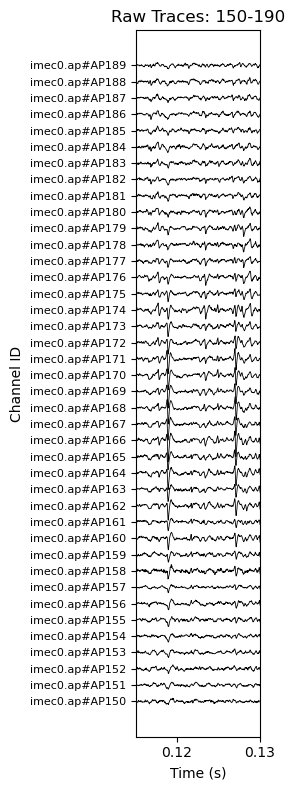

In [9]:
import matplotlib.pyplot as plt
import numpy as np

def plot_raw_traces(recording, ch_range=(120, 170), t_range=(0.11, 0.13), figsize=(6, 10)):
    """
    Plots raw traces with Channel IDs on the Y-axis.
    
    Parameters:
    - recording: SpikeInterface recording object
    - ch_range: tuple of (start_index, end_index)
    - t_range: tuple of (start_time, end_time) in seconds
    - figsize: tuple for the (width, height) of the plot
    """
    # 1. Setup metadata
    fs = recording.get_sampling_frequency()
    start_frame = int(t_range[0] * fs)
    end_frame = int(t_range[1] * fs)
    
    # Get the specific channel IDs
    all_ids = recording.get_channel_ids()
    target_ids = all_ids[ch_range[0]:ch_range[1]]
    
    # 2. Extract traces (samples, channels)
    traces = recording.get_traces(start_frame=start_frame, 
                                  end_frame=end_frame, 
                                  channel_ids=target_ids)
    
    # 3. Plotting
    fig, ax = plt.subplots(figsize=figsize, facecolor='white')
    t = np.linspace(t_range[0], t_range[1], traces.shape[0])
    
    # Calculate vertical spacing (Scaling factor 10 is usually good for LFP)
    v_spacing = np.median(np.std(traces, axis=0)) * 10 
    offsets = np.arange(len(target_ids)) * v_spacing
    
    for i in range(len(target_ids)):
        y_signal = traces[:, i] - np.mean(traces[:, i])
        ax.plot(t, y_signal + offsets[i], color='black', lw=0.6)
    
    # 4. Formatting
    ax.set_yticks(offsets)
    ax.set_yticklabels(target_ids, fontsize=8)
    ax.set_title(f"Raw Traces: {ch_range[0]}-{ch_range[1]}", fontsize=12)
    ax.set_xlabel("Time (s)", fontsize=10)
    ax.set_ylabel("Channel ID", fontsize=10)
    ax.set_xlim(t_range[0], t_range[1])
    
    plt.tight_layout()
    return fig

# --- HOW TO CALL IT ---
# To get a narrow plot for your slide:
fig = plot_raw_traces(rec0, ch_range=(150, 190), t_range=(0.115, 0.13), figsize=(3, 8))
fig.savefig("slide_figure.png", dpi=300)
plt.show()

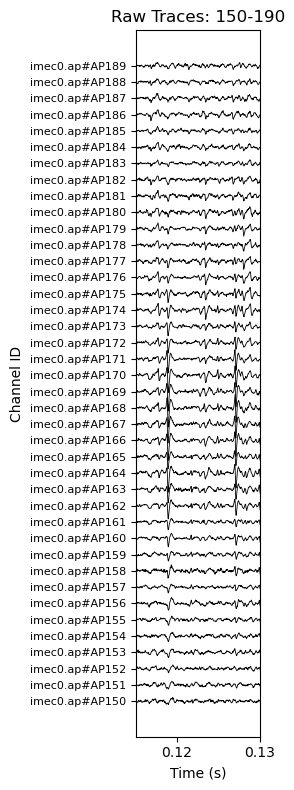

In [16]:
rec1 = si.highpass_filter(rec0)
rec2 = si.common_reference(rec1, reference='global', operator='median')
rec3 = si.zscore(rec2,mode='median+mad')
fig = plot_raw_traces(rec3, ch_range=(150, 190), t_range=(0.115, 0.13), figsize=(3, 8))

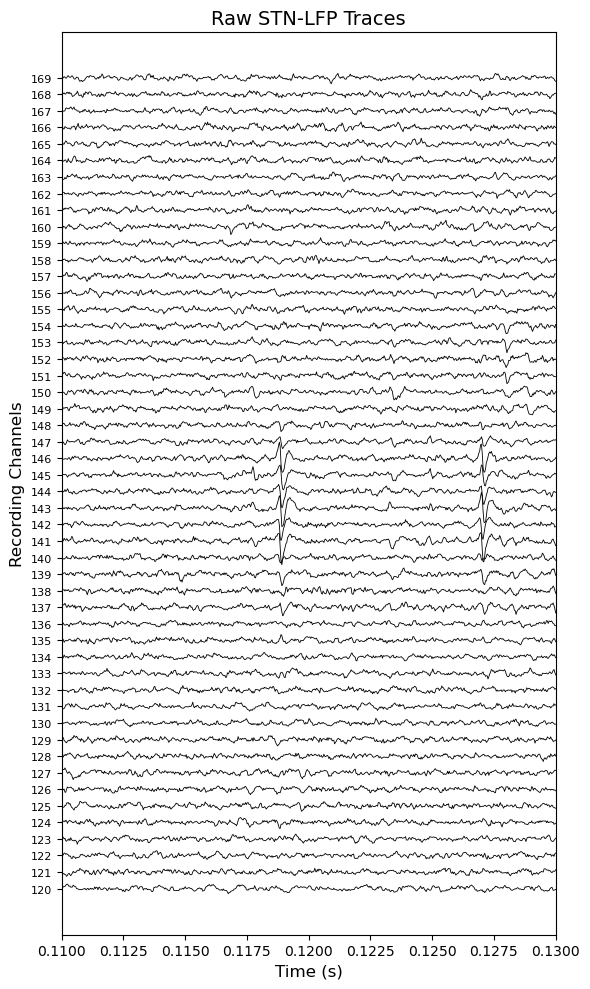

In [12]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Manually pull the data
recording = ks_preprocessed_rec
fs = recording.get_sampling_frequency()
start_frame = int(0.11 * fs)
end_frame = int(0.13 * fs)

# Select range and get the ACTUAL IDs for the labels
channel_indices = np.arange(120, 170)
target_channels = [recording.get_channel_ids()[i] for i in channel_indices]

# Extract data (samples, channels)
traces = recording.get_traces(start_frame=start_frame, 
                              end_frame=end_frame, 
                              channel_ids=target_channels)

# 2. Plotting - Adjusted figsize to be "less wide" (e.g., 6x10 instead of 12x6)
plt.figure(figsize=(6, 10), facecolor='white')
t = np.linspace(0.11, 0.13, traces.shape[0])

# Vertical spacing: Increase the '10' if traces overlap too much
v_spacing = np.median(np.std(traces, axis=0)) * 10 
offsets = np.arange(len(target_channels)) * v_spacing

for i in range(len(target_channels)):
    # Normalize trace and apply offset
    y_signal = traces[:, i] - np.mean(traces[:, i])
    plt.plot(t, y_signal + offsets[i], color='black', lw=0.6)

# 3. Setting Y-axis to Channel IDs
plt.yticks(offsets, target_channels, fontsize=8)
plt.title("Raw STN-LFP Traces", fontsize=14)
plt.xlabel("Time (s)", fontsize=12)
plt.ylabel("Recording Channels", fontsize=12)

plt.xlim(0.11, 0.13)
plt.tight_layout()

# 4. Save for your slide
plt.savefig("narrow_traces_with_ids.png", dpi=300)
plt.show()

In [ ]:
plot_spikes_on_trace(preprocessed_rec, preprocessed_rec, templates, spike_templates, spike_times, spike_clusters, fs, active_channel_threshold, time_range, sorter_output, rec_name = 'preprocessed')

In [ ]:
rec_test = whiten(preprocessed_rec, mode='local', radius_um = 1000)

In [ ]:
plot_spikes_on_trace(rec_test, preprocessed_rec, templates, spike_templates, spike_times, spike_clusters, fs, active_channel_threshold, time_range, sorter_output, rec_name = 'si_whitened_loc1000')

In [ ]:
rec = preprocessed_rec
time_range = (7.4, 7.5)
rec_name = 'preprocessed'
### find best channel for each spike ### 
template_amplitudes = np.max(np.abs(templates),axis=1) #n_templates, n_channels 
peak_channels_for_template = np.argmax(template_amplitudes, axis = 1) #n_templates

#map spikes to its template's peak channel 
all_spike_template_indices = spike_templates.flatten() 
all_spike_peak_channel = peak_channels_for_template[all_spike_template_indices]

### time window filtering ### 
start_samp = time_range[0]*fs
end_samp = time_range[1]*fs
# find a mask to filter only spikes in this time window 
in_window = (spike_times.flatten() > start_samp) & (spike_times.flatten() < end_samp)
in_window_spike_times = spike_times.flatten()[in_window]
in_window_spike_clusters = spike_clusters.flatten()[in_window]
in_window_spike_peak_channels = all_spike_peak_channel[in_window]
in_window_spike_template_indices = all_spike_template_indices[in_window]

print(f"Number of spikes in window: {len(in_window_spike_peak_channels)}")
print(f"Spike times shape: {in_window_spike_times.shape}")

active_channels_mask = template_amplitudes > active_channel_threshold
active_channel_counts = np.sum(active_channels_mask, axis = 1) 
max_channel_count = np.max(active_channel_counts)
template_index_max_channels = np.argmax(active_channel_counts)

sampling_freq = rec.get_sampling_frequency()  
channels = rec.get_channel_ids()
sample_window = 32
scale = 3
shading_amplitude_threshold = active_channel_threshold
time_range = list(time_range)

start_frame = int((time_range[0] + 550)* sampling_freq)
end_frame = int((time_range[1] + 550)* sampling_freq)

traces = rec.get_traces(channel_ids=channels, segment_index=0, start_frame=start_frame, end_frame=end_frame)
traces = traces * scale

vspacing = np.max(np.abs(traces)) * 1.2  
offsets = np.arange(traces.shape[1]) * vspacing
traces_offset = traces + offsets
time_vec = np.arange(start_frame, end_frame) / sampling_freq

plt.figure(figsize=(20, 90))
for ch in range(traces.shape[1]):
    plt.plot(time_vec, traces_offset[:, ch], color='black', lw=0.5)
'''
clusters = np.unique(in_window_spike_clusters)
n_colors = len(clusters)
cmap = plt.cm.get_cmap('tab20', 100) 

color_indices = []
step = 5 
for i in range(n_colors):
    color_index = (i * step) % cmap.N 
    color_indices.append(color_index)

cluster_color_dict = {}
for i, unit_id in enumerate(clusters):
    color = cmap(color_indices[i])
    cluster_color_dict[unit_id] = color

iterator = zip(
    in_window_spike_times, 
    in_window_spike_peak_channels, 
    in_window_spike_clusters, 
    in_window_spike_template_indices 
)
total_channels = len(channels) 

for st, ch_peak, cl, template_idx in tqdm(iterator, total=len(in_window_spike_times)):
    st_s = st / fs  # convert to seconds
    current_template_amplitudes = template_amplitudes[template_idx, :]
    for c in range(total_channels): 
        if current_template_amplitudes[c] > shading_amplitude_threshold:
            rect = patches.Rectangle(
                (st_s - sample_window/fs, offsets[c] - vspacing*0.49),  # (x, y)
                2*sample_window/fs,                                      # width
                vspacing*0.93,                                           # height
                color=cluster_color_dict[cl],
                alpha=0.3
            )
            plt.gca().add_patch(rect)
'''
channel_string_ids = preprocessed_rec.get_channel_ids()

plt.ylim(offsets[0] - vspacing*0.5, offsets[-1] + vspacing*0.5)
plt.xlabel('Time (s)')
plt.ylabel('Channels (offset)')
plt.title(f'Raw traces with cluster spike highlights (Template Amplitude > {shading_amplitude_threshold})')
plt.yticks(offsets, channel_string_ids)

plt.savefig(os.path.join(sorter_output, f'trace_visualise_{rec_name}_{shading_amplitude_threshold}_{time_range[0]}_{time_range[1]}.png'))
plt.show()

## OTHER VISUALISATION

In [ ]:
compute_dict = {
    'random_spikes': {}, #random spike selection across units 
    'correlograms':{'bin_ms': 0.1},
    'waveforms':{},
    'principal_components':{'n_components': 6, 'whiten':False},
    'templates':{},
    'spike_amplitudes':{},
    'template_similarity':{}, 
    'unit_locations':{}, 
    'spike_amplitudes':{},
    'template_similarity':{}, 
    'unit_locations':{}, 
}

In [ ]:
def smart_compute(analyzer_save, compute_dict, sorting):
    if os.path.exists(analyzer_save):
        print("analyzer folder exists, loading extensions...")
        sorting_analyzer = si.load_sorting_analyzer(folder = analyzer_save, format = 'binary_folder')
    else: 
        print("analyzer folder does not exist, creating new analyzer...")
        sorting_analyzer = si.create_sorting_analyzer(sorting = sorting, recording = preprocessed_rec, format = 'binary_folder', folder = analyzer_save)
    
    existing_exts = sorting_analyzer.get_loaded_extension_names()
    print("already available:", existing_exts)

    to_compute = {
        ext: params for ext, params in compute_dict.items() if ext not in existing_exts
    }
    print("need to compute:", list(to_compute.keys()))

    if len(to_compute) > 0: 
        print("computing...")
        sorting_analyzer.compute(to_compute, save = True, progress_bar = True, n_jobs = 8)
    
    return sorting_analyzer 

In [ ]:
sorting_analyzer = smart_compute(analyzer_save, compute_dict, sorting) 

In [ ]:
### SORTING VIEW ### 
os.environ['KACHERY_API_KEY'] = 'jyLIkvZqymHoejf8Nq6rpLZp4JUmU0XS'
os.environ["KACHERY_USER_EMAIL"] = "tingchen.gong@brain.mpg.de"
#summary = sw.plot_sorting_summary(sorting_analyzer=sorting_analyzer, curation = True, backend = 'sortingview')

In [ ]:
%matplotlib widget

In [ ]:
import matplotlib.pyplot as plt
import spikeinterface.widgets as sw
import numpy as np

unit_ids = sorting_analyzer.unit_ids
unit_colors_dict = {unit_id: 'gray' for unit_id in unit_ids}
target_unit_id = 3
target_unit_colors = {target_unit_id: 'blue'}
bins_count = 500 # Use 100 bins for the histogram

fig, axes = plt.subplots(
    nrows=1, ncols=2, 
    figsize=(16, 6), 
    gridspec_kw={'width_ratios': [4, 1], 'wspace': 0.05}
)

ax_amp = axes[0] 
ax_hist = axes[1] 

w_all = sw.plot_amplitudes(
    sorting_analyzer, 
    unit_colors=unit_colors_dict, 
    plot_legend=False, 
    backend='matplotlib',
    ax=ax_amp 
)

y_lim = ax_amp.get_ylim()
print(f"The initial Y-limits are: {y_lim}")

sw.plot_amplitudes(
    sorting_analyzer, 
    unit_ids=[target_unit_id], 
    y_lim=y_lim, 
    unit_colors=target_unit_colors, 
    plot_legend=False,
    ax=ax_amp, 
    backend='matplotlib'
)

data_plot = w_all.data_plot
all_y_data = data_plot['y_axis_data'] 
target_amplitudes = all_y_data.get(target_unit_id)

if target_amplitudes is not None and len(target_amplitudes) > 0:
    ax_hist.hist(
        target_amplitudes, 
        bins=bins_count, 
        orientation='horizontal', 
        range=y_lim,           
        color='blue',
        alpha=0.7
    )
    ax_hist.set_ylim(y_lim) 
else:
    print(f"No amplitude data found for unit {target_unit_id} or unit list is empty.")

ax_hist.tick_params(labelleft=False) 
ax_hist.set_ylabel("Count") 
ax_amp.set_title(f"Amplitude: Unit {target_unit_id}")

plt.show()

In [ ]:
sw.plot_autocorrelograms(sorting_analyzer, unit_ids = [target_unit_id], unit_colors = target_unit_colors)

In [ ]:
num_channels_to_plot = 32
max_spikes_to_plot = 100 

unit_index = target_unit_id 
template = templates[unit_index] 
template_amplitudes = np.max(np.abs(template), axis=0) 
sorted_indices = np.argsort(template_amplitudes)[::-1]
top_channels_indices = sorted_indices[:num_channels_to_plot]
template_top_32 = template[:, top_channels_indices]
channel_map_indices = channel_map[top_channels_indices] 

data_path = ks_preprocessed_file
n_channels_total = nchan
n_samples = template.shape[1]
half_sample_size = (n_samples-1) // 2

data_dtype = 'float32'
raw_data = np.memmap(data_path, dtype=data_dtype, mode='r')
data_shape = (raw_data.size // n_channels_total, n_channels_total)
raw_data = raw_data.reshape(data_shape)

unit_mask = (spike_clusters.flatten() == target_unit_id)
unit_spike_times = spike_times.flatten()[unit_mask]

if len(unit_spike_times) > max_spikes_to_plot:
    rand_indices = np.random.choice(len(unit_spike_times), max_spikes_to_plot, replace=False)
    sampled_spike_times = unit_spike_times[rand_indices]
else:
    sampled_spike_times = unit_spike_times

n_samples = template.shape[1] 
n_total_samples = raw_data.shape[0]
waveforms = []
valid_spikes_count = 0 
for t in sampled_spike_times:
    t = int(t)
    start_time = t - half_sample_size
    end_time = t + half_sample_size
    if start_time < 0 or end_time > n_total_samples:
        continue
    snippet = raw_data[start_time:end_time, channel_map_indices]
    if snippet.shape[0] == n_samples:
        waveforms.append(snippet)
        valid_spikes_count += 1
    else:
        continue
waveforms = np.array(waveforms)
print(f"Extracted {valid_spikes_count} valid waveforms (Original sampled count: {len(sampled_spike_times)}).")
print(f"Extracted waveforms shape: {waveforms.shape}")

nrows = 8
ncols = 4
fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(12, 16))
fig.suptitle(f"Unit {target_unit_id} Waveforms (Top {num_channels_to_plot} Channels)", fontsize=16)
axes = axes.flatten()

v_min = np.min(waveforms)
v_max = np.max(waveforms)
y_span = v_max - v_min
amplitude_scale = 0.1 
time_points = np.arange(n_samples)

for i in range(num_channels_to_plot):
    ax = axes[i]
    for j in range(waveforms.shape[0]):
        ax.plot(time_points, waveforms[j, :, i], 
                color='blue', alpha=0.1, linewidth=0.5)
    ax.plot(time_points, template_top_32[:, i], 
            color='black', linewidth=2.0, label='Template')
    ax.set_title(f"Channel {channel_map_indices[i]}", fontsize=8)
    ax.set_ylim(v_min - y_span * amplitude_scale, v_max + y_span * amplitude_scale)
    ax.set_xticks([])
    ax.set_yticks([])

if num_channels_to_plot < len(axes):
    for j in range(num_channels_to_plot, len(axes)):
        fig.delaxes(axes[j])
        
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

In [ ]:
#sw.plot_sorting_summary(sorting_analyzer, curation = True, backend = 'sortingview')